In [2]:
%pip install "geopandas[all]" -q

Note: you may need to restart the kernel to use updated packages.


In [3]:
from pathlib import Path

import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
from shapely import wkt

output_dir_vis = Path("./vis")
output_dir_vis.mkdir(exist_ok=True)

In [4]:
tract_housing_growth = pd.read_csv("data/tract_housing_growth.csv")
tract_housing_growth

,GEOID,net_units_added
0,6075010101,0
1,6075010102,15
2,6075010201,10
3,6075010202,52
4,6075010300,43
...,...,...
239,6075980501,0
240,6075980600,0
241,6075980900,3
242,6075990100,0


In [5]:
census_tracts = pd.read_csv("data/Census_2020__Tracts_for_San_Francisco.csv")
census_tracts

,the_geom,STATEFP,COUNTYFP,TRACTCE,GEOID,NAME,NAMELSAD,MTFCC,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,data_loaded_at,data_as_of
0,MULTIPOLYGON (((-122.427223 37.715548999999996...,6,75,980501,6075980501,9805.01,Census Tract 9805.01,G5020,S,"1,471,536","9,769",37.716208,-122.419346,2022 Mar 04 12:00:00 AM,2021 Feb 01 12:00:00 AM
1,"MULTIPOLYGON (((-122.453206 37.768249, -122.45...",6,75,17102,6075017102,171.02,Census Tract 171.02,G5020,S,"294,894",0,37.765435,-122.450475,2022 Mar 04 12:00:00 AM,2021 Feb 01 12:00:00 AM
2,"MULTIPOLYGON (((-122.414995 37.787454, -122.41...",6,75,12302,6075012302,123.02,Census Tract 123.02,G5020,S,"92,653",0,37.787022,-122.412097,2022 Mar 04 12:00:00 AM,2021 Feb 01 12:00:00 AM
3,"MULTIPOLYGON (((-122.432351 37.773779, -122.43...",6,75,16801,6075016801,168.01,Census Tract 168.01,G5020,S,"226,534",0,37.771331,-122.429013,2022 Mar 04 12:00:00 AM,2021 Feb 01 12:00:00 AM
4,"MULTIPOLYGON (((-122.41246100000001 37.791627,...",6,75,11902,6075011902,119.02,Census Tract 119.02,G5020,S,"93,053",0,37.790996,-122.409807,2022 Mar 04 12:00:00 AM,2021 Feb 01 12:00:00 AM
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
239,"MULTIPOLYGON (((-122.426462 37.766272, -122.42...",6,75,20201,6075020201,202.01,Census Tract 202.01,G5020,S,"140,617",0,37.764788,-122.424095,2022 Mar 04 12:00:00 AM,2021 Feb 01 12:00:00 AM
240,MULTIPOLYGON (((-122.393618 37.783077999999996...,6,75,61508,6075061508,615.08,Census Tract 615.08,G5020,S,"227,943","152,297",37.785752,-122.386381,2022 Mar 04 12:00:00 AM,2021 Feb 01 12:00:00 AM
241,"MULTIPOLYGON (((-122.430747 37.798648, -122.42...",6,75,13001,6075013001,130.01,Census Tract 130.01,G5020,S,"181,456",0,37.797663,-122.427228,2022 Mar 04 12:00:00 AM,2021 Feb 01 12:00:00 AM
242,"MULTIPOLYGON (((-122.424835 37.802268, -122.42...",6,75,10201,6075010201,102.01,Census Tract 102.01,G5020,S,"186,873",0,37.801303,-122.421215,2022 Mar 04 12:00:00 AM,2021 Feb 01 12:00:00 AM


In [6]:
housing_production_located = pd.read_csv("data/housing_production_located.csv")
housing_production_located

,BPA,Address,Description,PTS Existing Units,PTS Proposed Units,Proposed Units,Net Units,Net Units Completed,ADU/Legalization Units,First Completion Date,...,Authorization Date,Zoning District,Project Affordability Type,BMR Reporting Year,BlockLot,PPTS Project ID,latitude,longitude,match_status,match_note
0,1801Wedemeyer,1801 Wedemeyer St,PRESIDIO LANDMARK 100 1-BR; 54 2-BR (Federal l...,0,NaN,154,154,154,0,06/30/2010,...,04/27/2007,P,NaN,2010,1300001,NaN,NaN,NaN,unmatched,no_parcel_match
1,20000109571,360 BENTON AV,"TO ERECT A NEW 3 STORY, 2 UNIT RESIDENTIAL BUI...",0,2.0,2,2,2,0,12/08/2008,...,08/29/2006,RH-2,NaN,2008,5828012,2007.0150,NaN,NaN,unmatched,no_parcel_match
2,20000112863,340 BENTON AV,TO ERECT A NEW 3 STORY 2 FAMILY DWELLING RESID...,0,2.0,2,2,2,0,12/08/2008,...,08/29/2006,RH-2,NaN,2008,5828011,NaN,NaN,NaN,unmatched,no_parcel_match
3,20000112908,505 KIRKHAM ST,ERECT 4 STORY 2 FAMILY DWELLING UNIT,0,2.0,2,2,2,0,11/15/2005,...,09/01/2004,RH-2,NaN,2005,1855045,2003.0545,NaN,NaN,unmatched,no_parcel_match
4,20000118277,1810 POLK ST,"TO ERECT 12 DWELLING UNITS, 4 STORIES, RESIDEN...",0,12.0,12,12,12,0,09/29/2006,...,01/05/2005,NCD-POLK,Incl: On-Site BMR,2006,0597016,2000.051,NaN,NaN,unmatched,no_parcel_match
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4813,9924082S,871 JAMESTOWN AV,BLDG #6 - ERECT A 3 STORIES OF EIGHTEEN UNITS ...,0,18.0,18,18,18,0,08/20/2014,...,08/16/2006,RH-2,100% Affordable,2014,4991277,1999.233,NaN,NaN,unmatched,no_parcel_match
4814,9925758S,981 GREENWICH ST,ERECT A THREE STORY THREE UNIT RESIDENTIAL BLDG,0,3.0,3,3,3,0,07/21/2005,...,08/03/2001,RM-1,NaN,2005,0092044,2002.0792,NaN,NaN,unmatched,no_parcel_match
4815,9927159S,380 BENTON AV,"TO ERECT A NEW 3 STORY, 2 UNIT RESIDENTIAL BUI...",0,2.0,2,2,2,0,12/08/2008,...,08/31/2006,RH-2,NaN,2008,5828013,2007.0151,NaN,NaN,unmatched,no_parcel_match
4816,Academe 198,198 McAllister St,SF Law graduate student housing – Majority of ...,0,NaN,657,657,657,0,08/15/2023,...,02/01/2023,P,NaN,2023,0348009,2025-008348PRX,NaN,NaN,unmatched,no_parcel_match


In [7]:
sf_land_use_clean = pd.read_csv("data/sf_land_use_clean.csv")
sf_land_use_clean

,mapblklot,centroid_latitude,centroid_longitude,residential_units,has_special_residential_units,residential_use,geography_type,major_multiphase_project,special_jurisdiction,is_megaproject,is_special_housing,is_special_jurisdiction
0,"'3791002', '3791001', '3790001'",37.783644,-122.388816,177,False,NaN,multiple_parcels,NaN,NaN,False,False,False
1,"'3773577', '3773300A', '3773291', '3773200A', ...",37.784916,-122.389736,863,False,NaN,multiple_parcels,NaN,NaN,False,False,False
2,"'0026T001A', '0026028'",37.805473,-122.420596,24,False,NaN,multiple_parcels,NaN,NaN,False,False,False
3,"'0732001', '0732002', '0732004', '0732028', '0...",37.782041,-122.431272,120,False,NaN,multiple_parcels,NaN,NaN,False,False,False
4,"'0767005', '0767009', '0767007', '0767001', '0...",37.780507,-122.421121,0,False,NaN,multiple_parcels,NaN,NaN,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...
153749,4909002,37.720837,-122.388865,2,False,NaN,parcel,NaN,NaN,False,False,False
153750,7135022,37.711214,-122.464091,3,False,NaN,parcel,NaN,NaN,False,False,False
153751,1707001,37.764139,-122.503185,2,False,NaN,parcel,NaN,NaN,False,False,False
153752,3732096,37.780605,-122.404704,8,False,NaN,parcel,NaN,NaN,False,False,False


In [8]:
sf_land_use_clean["residential_units"]

0         177
1         863
2          24
3         120
4           0
         ... 
153749      2
153750      3
153751      2
153752      8
153753      3
Name: residential_units, Length: 153754, dtype: int64

In [9]:
sf_land_use_clean.columns

Index(['mapblklot', 'centroid_latitude', 'centroid_longitude',
       'residential_units', 'has_special_residential_units', 'residential_use',
       'geography_type', 'major_multiphase_project', 'special_jurisdiction',
       'is_megaproject', 'is_special_housing', 'is_special_jurisdiction'],
      dtype='object')

In [10]:
# Convert land use dataframe to a GeoDataFrame using its centroid coordinates
land_use_gdf = gpd.GeoDataFrame(
    sf_land_use_clean,
    geometry=gpd.points_from_xy(sf_land_use_clean.centroid_longitude, sf_land_use_clean.centroid_latitude),
    crs="EPSG:4326"  # Standard WGS84 coordinate reference system
)

In [11]:
# Convert the 'the_geom' string column into actual shapely geometries using shapely.wkt
census_tracts['geometry'] = census_tracts['the_geom'].apply(wkt.loads)

# Create the census tracts GeoDataFrame
census_tracts_gdf = gpd.GeoDataFrame(census_tracts, geometry='geometry', crs="EPSG:4326")

In [12]:
# Spatial join: find which census tract polygon contains each land use point
land_use_with_tract = gpd.sjoin(
    land_use_gdf, 
    census_tracts_gdf[['GEOID', 'geometry']], 
    how="inner", 
    predicate="within"
)

In [13]:
# Sum residential units by GEOID
tract_2008_baseline = (
    land_use_with_tract.groupby("GEOID")["residential_units"]
    .sum()
    .reset_index(name="units_2008")
)

tract_2008_baseline.head()

,GEOID,units_2008
0,6075010101,1736
1,6075010102,972
2,6075010201,1775
3,6075010202,1762
4,6075010300,2391


In [14]:
# 1. Join permits with land use to assign a GEOID to each permit
housing_permits_joined = pd.merge(
    housing_production_located,
    land_use_with_tract[['mapblklot', 'GEOID']].drop_duplicates(subset=['mapblklot']),
    left_on='BlockLot',
    right_on='mapblklot',
    how='inner'
)

# 2. Extract the completion year
housing_permits_joined['completed_year'] = pd.to_datetime(
    housing_permits_joined['First Completion Date'], 
    errors='coerce'
).dt.year

# 3. Filter for permits completed between 2005 and 2008
permits_05_08 = housing_permits_joined[
    (housing_permits_joined['completed_year'] >= 2005) & 
    (housing_permits_joined['completed_year'] <= 2008)
]

# 4. Sum net units completed (2005-2008) by tract
units_05_08_by_tract = (
    permits_05_08.groupby("GEOID")["Net Units Completed"]
    .sum()
    .reset_index(name="net_units_2005_2008")
)

# 5. Merge with 2008 land use baseline (tract_2008_baseline) and calculate 2005 baseline
baseline_2005 = pd.merge(tract_2008_baseline, units_05_08_by_tract, on="GEOID", how="left")
baseline_2005["net_units_2005_2008"] = baseline_2005["net_units_2005_2008"].fillna(0)

# Calculate 2005 starting stock
baseline_2005["baseline_2005_stock"] = (
    baseline_2005["units_2008"] - baseline_2005["net_units_2005_2008"]
)

In [15]:
# 1. Merge your total net units added with your 2005 baseline stock using GEOID
final_growth_df = pd.merge(
    tract_housing_growth, 
    baseline_2005[['GEOID', 'baseline_2005_stock']], 
    on="GEOID", 
    how="inner"
)

# 2. Calculate the Growth Rate percentage 
# Formula: (Net Units Added / Baseline Housing Stock) * 100[cite: 1]
final_growth_df["growth_rate_pct"] = (
    final_growth_df["net_units_added"] / final_growth_df["baseline_2005_stock"]
) * 100

# 3. View your final results!
final_growth_df.sort_values(by="growth_rate_pct", ascending=False)

,GEOID,net_units_added,baseline_2005_stock,growth_rate_pct
220,6075060702,1319,1397.0,94.416607
117,6075022600,1618,3384.0,47.813239
89,6075017803,531,1179.0,45.038168
86,6075017604,1942,4439.0,43.748592
131,6075023300,341,1337.0,25.504862
...,...,...,...,...
234,6075061507,0,1514.0,0.000000
237,6075980300,0,42.0,0.000000
238,6075980501,0,91.0,0.000000
239,6075980600,0,930.0,0.000000


In [16]:
baseline_2005.to_csv("sf_census_tract_baseline_housing_2005.csv", index=False)

In [17]:
final_growth_df.to_csv("sf_census_tract_housing_growth_rates_2005_2025.csv", index=False)

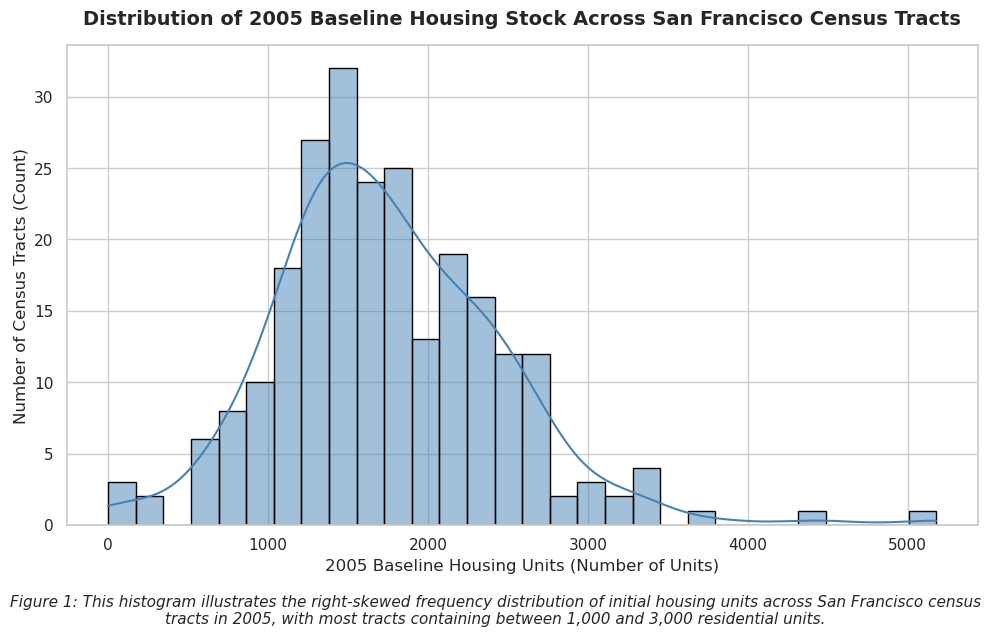

In [18]:
#Visualization 1: Distribution of 2005 Baseline Housing Stock Across Census Tracts
import matplotlib.pyplot as plt
import seaborn as sns

# Set style
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

# Plot histogram and KDE of 2005 baseline housing stock
sns.histplot(
    baseline_2005['baseline_2005_stock'], 
    bins=30, 
    kde=True, 
    color='steelblue', 
    edgecolor='black'
)

# Add titles, labels, and units
plt.title("Distribution of 2005 Baseline Housing Stock Across San Francisco Census Tracts", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("2005 Baseline Housing Units (Number of Units)", fontsize=12)
plt.ylabel("Number of Census Tracts (Count)", fontsize=12)

# One-sentence caption
plt.figtext(
    0.5, -0.05, 
    "Figure 1: This histogram illustrates the right-skewed frequency distribution of initial housing units across San Francisco census tracts in 2005, with most tracts containing between 1,000 and 3,000 residential units.", 
    wrap=True, horizontalalignment='center', fontsize=11, fontstyle='italic'
)

plt.tight_layout()
plt.savefig("baseline_housing_distribution_2005.png", dpi=300, bbox_inches='tight')
plt.show()

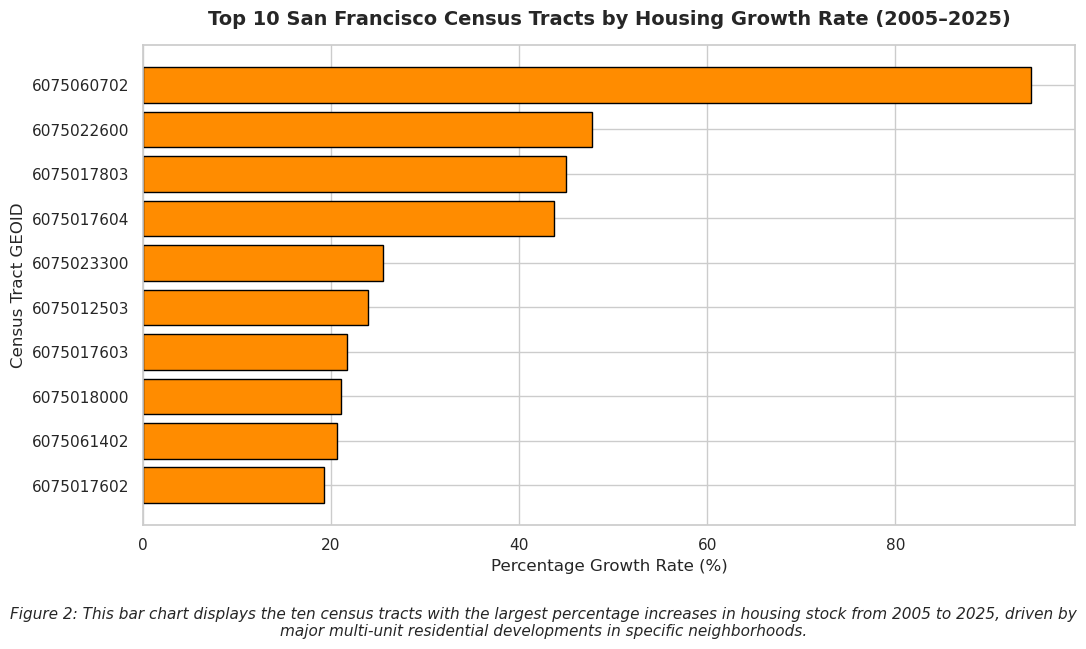

In [19]:
#Visualization 2: Top 10 Census Tracts by Percentage Housing Growth (2005–2025)
plt.figure(figsize=(11, 6))

# Sort and select top 10 tracts by growth rate percentage
top_growth = final_growth_df.sort_values(by="growth_rate_pct", ascending=False).head(10)

# Create horizontal bar chart
bars = plt.barh(
    y=top_growth['GEOID'].astype(str), 
    width=top_growth['growth_rate_pct'], 
    color='darkorange', 
    edgecolor='black'
)

# Invert y-axis so the highest growth is at the top
plt.gca().invert_yaxis()

# Add titles, labels, and units
plt.title("Top 10 San Francisco Census Tracts by Housing Growth Rate (2005–2025)", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Percentage Growth Rate (%)", fontsize=12)
plt.ylabel("Census Tract GEOID", fontsize=12)

# One-sentence caption
plt.figtext(
    0.5, -0.07, 
    "Figure 2: This bar chart displays the ten census tracts with the largest percentage increases in housing stock from 2005 to 2025, driven by major multi-unit residential developments in specific neighborhoods.", 
    wrap=True, horizontalalignment='center', fontsize=11, fontstyle='italic'
)

plt.tight_layout()
plt.savefig("top_housing_growth_tracts.png", dpi=300, bbox_inches='tight')
plt.show()